In [41]:
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_excel("../data/DATOS_TEC.xlsx")
df.head()

,Unnamed: 0,CodigoProducto,Familia,Aceite_Base,Carga_Timken_Ok_lb,Corrosión_al_Cobre,Desgaste_Cuatro_Bolas_mm,Espesante,Estabilidad_Mecánica_%,Factor_de_Velocidad,Grado_ISO_VG,Grado_NLGI_Consistencia,Indice_de_Viscosidad,Penetración_de_Cono_a_25°C_0.1mm,Peso_Específico,Punto_de_Congelamiento_°C,Punto_de_Flama_°C,Punto_de_Gota_°C,Punto_de_Soldadura_Cuatro_Bolas_kgf,Registro_NSF,Resistencia_al_Lavado_por_Agua_a_80°C_%,Temperatura_de_Servicio_°C_max,Temperatura_de_Servicio_°C_min,Viscosidad_a_100°C_cSt,Viscosidad_a_40°C_cSt,Viscosidad_del_Aceite_Base_a_40°C._cSt,Color,Textura,Color_Numerico_Min,Estabilidad_Mecanica_Min,Indice_de_Viscosidad_Min,Lavado_por_Agua_Min,Penetracion_1_10_Min,Penetracion_a_10_000_Min,Penetracion_a_60_Min,Peso_Especifico_Min,Punto_de_Flama_Min,Punto_de_Gota_Min,Punto_de_Ignicion_Min,TAN_MG_KOH_G_Min,Viscosidad_100_C_Min,Viscosidad_40_C_Min,Color_Numerico_Max,Estabilidad_Mecanica_Max,Indice_de_Viscosidad_Max,Lavado_por_Agua_Max,Penetracion_1_10_Max,Penetracion_a_10_000_Max,Penetracion_a_60_Max,Peso_Especifico_Max,Punto_de_Flama_Max,Punto_de_Gota_Max,Punto_de_Ignicion_Max,TAN_MG_KOH_G_Max,Viscosidad_100_C_Max,Viscosidad_40_C_Max,Color_Numerico_Estandar,Estabilidad_Mecanica_Estandar,Indice_de_Viscosidad_Estandar,Lavado_por_Agua_Estandar,Penetracion_1_10_Estandar,Penetracion_a_10_000_Estandar,Penetracion_a_60_Estandar,Peso_Especifico_Estandar,Punto_de_Flama_Estandar,Punto_de_Gota_Estandar,Punto_de_Ignicion_Estandar,TAN_MG_KOH_G_Estandar,Viscosidad_100_C_Estandar,Viscosidad_40_C_Estandar,Color_Visual_Valor,Deteccion_de_Grumo_Valor,Extrema_Presion_Valor,Grado_ISO_VG_Valor,Grado_NLGI_Valor,Inspeccion_Visual_Valor,Textura_Valor
0,1,Producto_1,Grasa,Ester,60,NaN,0.5,Bentonita,NaN,NaN,NaN,0.0,NaN,350 - 370,NaN,NaN,NaN,200,800,NaN,NaN,140.0,5.0,NaN,NaN,2600,Negro,Adherente,NaN,NaN,NaN,NaN,350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,380.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,360.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Negro Estandar,Sin Grumo,>= 600 kg,NaN,NaN,NaN,NaN
1,2,Producto_2,Grasa,Mineral,60,NaN,0.3,Complejo Sulfonato de Calcio,1.2,150000.0,NaN,1.0,NaN,320,NaN,NaN,NaN,304,500,NaN,NaN,190.0,-5.0,NaN,NaN,1000,Café Claro,Adherente,NaN,0.0,NaN,0.0,310.0,0.0,0.0,NaN,NaN,250.0,NaN,NaN,NaN,NaN,NaN,6.0,NaN,0.5,330.0,999999.0,999999.0,NaN,NaN,999999.0,NaN,NaN,NaN,NaN,NaN,6.0,NaN,0.5,320.0,0.0,0.0,NaN,NaN,250.0,NaN,NaN,NaN,NaN,Café Estandar,Sin Grumo,NaN,NaN,1.0,NaN,Suave
2,3,Producto_3,Aceite,Semi-Sintetico,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,-55.0,210,NaN,NaN,NaN,NaN,150.0,-10.0,NaN,NaN,NaN,Negro,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999999.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9,NaN,NaN,NaN,NaN,NaN,NaN,Negro Estandar,NaN,NaN,NaN,NaN,Cristalino,NaN
3,4,Producto_4,Aceite,Semi-Sintetico,NaN,NaN,NaN,NaN,NaN,NaN,32.0,NaN,200,NaN,0.9,-45.0,260,NaN,NaN,NaN,NaN,NaN,NaN,7.2,32,NaN,Ambar Ligero,NaN,0.0,NaN,160.0,NaN,NaN,NaN,NaN,0.8,230.0,NaN,0.0,0.0,0.0,30.4,1.0,NaN,999999.0,NaN,NaN,NaN,NaN,999999.0,999999.0,NaN,999999.0,0.5,999999.0,33.6,1.0,NaN,160.0,NaN,NaN,NaN,NaN,0.8,230.0,NaN,0.0,0.5,0.0,32.0,NaN,NaN,NaN,32.0,NaN,Cristalino,NaN
4,5,Producto_5,Grasa,Mineral,50,1a,0.48,Poliurea,6.5,200000.0,NaN,1.0,NaN,310,NaN,NaN,NaN,260,620,NaN,1.45,150.0,-10.0,NaN,NaN,680,Beige,Adherente,NaN,0.0,NaN,0.0,295.0,0.0,0.0,NaN,NaN,240.0,NaN,NaN,NaN,NaN,NaN,10.0,NaN,5.0,310.0,999999.0,999999.0,NaN,NaN,999999.0,NaN,NaN,NaN,NaN,NaN,5.0,NaN,2.5,300.0,0.0,0.0,NaN,NaN,240.0,NaN,NaN,NaN,NaN,Beige Estandar,Sin Grumo,>= 500 kg,NaN,NaN,NaN,Suave


In [42]:
# 1. Baseline: size, dtypes and heaviest missing columns (reference for every later step)
print(df.shape)
print(df.dtypes.value_counts())
df.isna().mean().mul(100).round(1).sort_values(ascending=False).head(10)

(341, 77)
float64    52
str        24
int64       1
Name: count, dtype: int64


Peso_Específico               79.8
Extrema_Presion_Valor         79.5
Registro_NSF                  78.9
Punto_de_Ignicion_Min         76.8
Grado_ISO_VG_Valor            76.8
Punto_de_Ignicion_Max         76.8
Punto_de_Ignicion_Estandar    76.8
Inspeccion_Visual_Valor       76.5
TAN_MG_KOH_G_Estandar         74.2
TAN_MG_KOH_G_Max              74.2
dtype: float64

In [43]:
# 2. Snake_case ascii names (no accents, °, %, dots) and drop the Excel index
def clean_name(c):
    c = c.replace("%", "pct")
    c = unicodedata.normalize("NFKD", c).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_")


df = df.drop(columns="Unnamed: 0", errors="ignore")
names = pd.DataFrame({"before": df.columns, "after": [clean_name(c) for c in df.columns]})
assert names["after"].is_unique
df.columns = names["after"].tolist()
names[names.before != names.after]

,before,after
0,CodigoProducto,codigoproducto
1,Familia,familia
2,Aceite_Base,aceite_base
3,Carga_Timken_Ok_lb,carga_timken_ok_lb
4,Corrosión_al_Cobre,corrosion_al_cobre
...,...,...
71,Extrema_Presion_Valor,extrema_presion_valor
72,Grado_ISO_VG_Valor,grado_iso_vg_valor
73,Grado_NLGI_Valor,grado_nlgi_valor
74,Inspeccion_Visual_Valor,inspeccion_visual_valor


In [44]:
# 3. Duplicates and fully empty rows/columns; also repeated specs under different product codes
shape_0 = df.shape
df = df.drop_duplicates().dropna(how="all").dropna(axis=1, how="all")
print(shape_0, "->", df.shape)
print("same specs, different code:", df.drop(columns="codigoproducto").duplicated().sum())

(341, 76) -> (341, 76)
same specs, different code: 0


In [45]:
# 4. Trim/collapse spaces in text, capitalize free-text labels and merge spelling variants
text_cols = df.select_dtypes(exclude="number").columns.drop("codigoproducto")
free_text = ["color", "textura", "color_visual_valor", "inspeccion_visual_valor", "textura_valor"]
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))
df[free_text] = df[free_text].apply(lambda s: s.str.replace(r"\b[a-z]", lambda m: m[0].upper(), regex=True))
df["color"] = df["color"].replace({"Roja": "Rojo"})
for c in ["familia", "aceite_base", "espesante", "color", "textura"]:
    print(c, df[c].value_counts().to_dict())

familia {'Grasa': 224, 'Aceite': 117}
aceite_base {'Mineral': 112, 'PAO': 75, 'Semi-Sintetico': 71, 'Ester': 47, 'Mineral USP': 26, 'PAG': 10}
espesante {'Complejo Sulfonato de Calcio': 81, 'Poliurea': 77, 'Complejo de Litio': 47, 'Bentonita': 19}
color {'Negro': 74, 'Beige': 62, 'Ambar': 36, 'Incoloro': 27, 'Blanco': 23, 'Amarillo Ligero': 17, 'Cristalino': 11, 'Gris': 10, 'Ambar Ligero': 9, 'Amarillo Claro': 9, 'Café Claro': 7, 'Ligero Verde': 6, 'Café': 5, 'Gris Metalico Aluminio': 5, 'Ambar Cristalino': 4, 'Amarillo': 4, 'Beige Claro': 4, 'Verde': 3, 'Rojo': 2, 'Ambar Claro': 2, 'Cobre': 2, 'Ambar-Verdoso': 1, 'Azul': 1}
textura {'Suave': 141, 'Adherente': 70, 'Suave Adherente': 9, 'Fluido Adherente': 3, 'Fluido Viscoso Adherente': 2, 'Suave Fluida': 2, 'Viscosa Adherente': 1}


In [46]:
# 5. Text columns that are really numeric: check which entries are not plain numbers (bounds, ranges, placeholders)
plain = r"^-?\d+(\.\d+)?$"
numeric_like = r"^[<>=\s]*\d+(\.\d+)?(\s*-\s*\d+(\.\d+)?)?\s*(kg)?$"
text_cols = df.select_dtypes(exclude="number").columns
num_cols = [c for c in text_cols if df[c].dropna().str.match(numeric_like).mean() > 0.9]
rows = []
for c in num_cols:
    s = df[c].dropna()
    odd = s[~s.str.match(plain)]
    rows.append({"column": c, "n_plain": len(s) - len(odd), "n_odd": len(odd), "examples": list(odd.unique()[:4])})
pd.DataFrame(rows).set_index("column")

,n_plain,n_odd,examples
column,,,
carga_timken_ok_lb,224,1,[> 40]
desgaste_cuatro_bolas_mm,157,1,[< 0.55]
estabilidad_mecanica_pct,173,6,"[< 10, < 5]"
indice_de_viscosidad,93,2,[> 120]
penetracion_de_cono_a_25c_0_1mm,181,44,"[350 - 370, 310 - 330, 265 - 295, 400 - 430]"
peso_especifico,33,36,"[> 0.8, > 0.9]"
punto_de_flama_c,96,15,"[> 200, > 210, > 295, > 240]"
punto_de_gota_c,208,6,"[> 240, > 180, > 250, > 200]"
punto_de_soldadura_cuatro_bolas_kgf,238,1,[TEST]


In [47]:
# 6. Convert to float as an interval: x -> (x, x), >x -> (x, NaN), <x -> (NaN, x), a - b -> (a, b)
pattern = re.compile(r"([<>]=?)?\s*(\d+(?:\.\d+)?)(?:\s*-\s*(\d+(?:\.\d+)?))?\s*(?:kg)?")


def parse(v):
    m = pattern.fullmatch(v) if isinstance(v, str) else None
    if not m:
        return np.nan, np.nan
    op, lo, hi = m.groups()
    if hi:
        return float(lo), float(hi)
    if op:
        return (float(lo), np.nan) if op[0] == ">" else (np.nan, float(lo))
    return float(lo), float(lo)


kinds = {}
for c in num_cols:
    low, high = pd.DataFrame(df[c].map(parse).tolist(), index=df.index).T.astype(float).values
    pos = df.columns.get_loc(c)
    df.insert(pos, c + "_low", low)
    df.insert(pos + 1, c + "_high", high)
    df = df.drop(columns=c)
    kinds[c] = {
        "exact": (low == high).sum(),
        "range": (low < high).sum(),
        "only_low (>x)": (~np.isnan(low) & np.isnan(high)).sum(),
        "only_high (<x)": (np.isnan(low) & ~np.isnan(high)).sum(),
        "empty": (np.isnan(low) & np.isnan(high)).sum(),
    }

print(df.dtypes.value_counts())
pd.DataFrame(kinds).T

float64    78
str        11
Name: count, dtype: int64


,exact,range,only_low (>x),only_high (<x),empty
carga_timken_ok_lb,224,0,1,0,116
desgaste_cuatro_bolas_mm,157,0,0,1,183
estabilidad_mecanica_pct,173,0,0,6,162
indice_de_viscosidad,93,0,2,0,246
penetracion_de_cono_a_25c_0_1mm,181,44,0,0,116
peso_especifico,33,0,36,0,272
punto_de_flama_c,96,0,15,0,230
punto_de_gota_c,208,0,6,0,127
punto_de_soldadura_cuatro_bolas_kgf,238,0,0,0,103
resistencia_al_lavado_por_agua_a_80c_pct,152,0,0,7,182


In [48]:
# 7. Placeholders for "no limit": all-9s (999..999999) or 0 in *_max, 0 in *_min and *_estandar (kept only where a real 0 is possible)
real_zero = ("color_numerico", "estabilidad_mecanica", "lavado_por_agua", "tan_mg_koh_g")
nines = [999, 9999, 99999, 999999]
limits = [c for c in df.columns if not c.startswith("temperatura")]
maxs = [c for c in limits if c.endswith("_max")]
zeros = [c for c in limits if c.endswith("_min") or (c.endswith("_estandar") and not c.startswith(real_zero))]

na_before = df.isna().sum()
df[maxs] = df[maxs].mask(df[maxs].isin(nines) | (df[maxs] == 0))
df[zeros] = df[zeros].mask(df[zeros] == 0)
for b in real_zero:  # a 0 standard with neither limit set is a placeholder too
    unset = df[b + "_min"].isna() & df[b + "_max"].isna() & (df[b + "_estandar"] == 0)
    df.loc[unset, b + "_estandar"] = np.nan
print("values turned into NaN:")
(df.isna().sum() - na_before).loc[lambda s: s > 0]

values turned into NaN:


color_numerico_min                84
estabilidad_mecanica_min         165
indice_de_viscosidad_min           1
lavado_por_agua_min              115
penetracion_1_10_min               8
penetracion_a_10_000_min         151
penetracion_a_60_min             114
peso_especifico_min                3
punto_de_flama_min                 1
punto_de_gota_min                  4
punto_de_ignicion_min             76
tan_mg_koh_g_min                  88
viscosidad_100_c_min              88
color_numerico_max                 2
estabilidad_mecanica_max           1
indice_de_viscosidad_max          86
penetracion_1_10_max               8
penetracion_a_10_000_max         150
penetracion_a_60_max             114
peso_especifico_max               92
punto_de_flama_max                83
punto_de_gota_max                170
punto_de_ignicion_max             79
tan_mg_koh_g_max                  10
viscosidad_100_c_max              86
color_numerico_estandar            2
estabilidad_mecanica_estandar      1
i

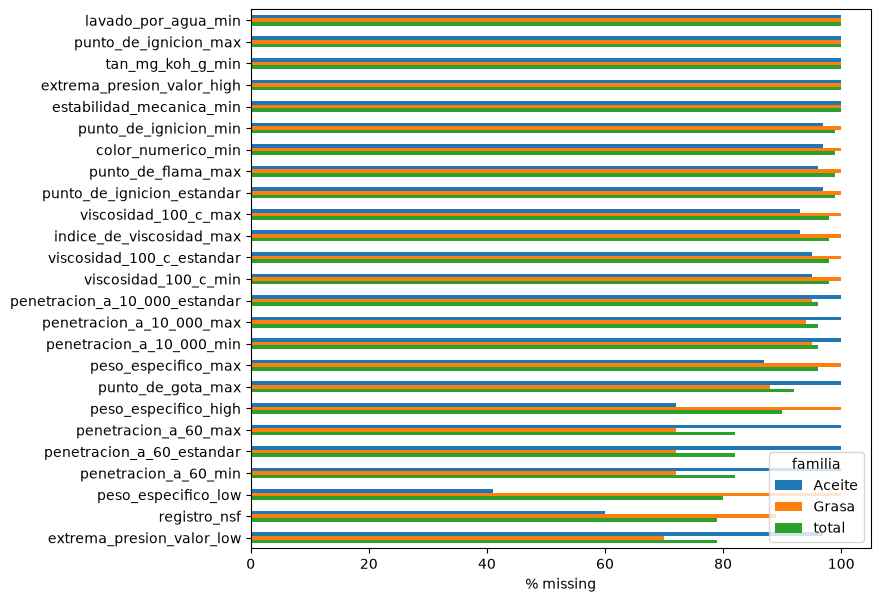

dropped (no values): ['estabilidad_mecanica_min', 'lavado_por_agua_min', 'tan_mg_koh_g_min', 'punto_de_ignicion_max', 'extrema_presion_valor_high'] | shape: (341, 84)


familia,Aceite,Grasa,total,n_filled
punto_de_ignicion_min,97.0,100.0,99.0,3
color_numerico_min,97.0,100.0,99.0,4
punto_de_flama_max,96.0,100.0,99.0,5
punto_de_ignicion_estandar,97.0,100.0,99.0,3
viscosidad_100_c_max,93.0,100.0,98.0,8
indice_de_viscosidad_max,93.0,100.0,98.0,8
viscosidad_100_c_estandar,95.0,100.0,98.0,6
viscosidad_100_c_min,95.0,100.0,98.0,6
penetracion_a_10_000_estandar,100.0,95.0,96.0,12
penetracion_a_10_000_max,100.0,94.0,96.0,13


In [49]:
# 8. Missing values: gaps are mostly structural (greases vs oils), so compare by family; drop only columns with no values at all
miss = df.drop(columns="familia").isna().groupby(df["familia"]).mean().T.mul(100).round(0)
miss["total"] = df.isna().mean().mul(100).round(0)
miss = miss.sort_values("total", ascending=False)
miss.head(25).plot.barh(figsize=(8, 7)).invert_yaxis()
plt.xlabel("% missing")
plt.show()

empty = df.columns[df.isna().all()]
df = df.drop(columns=empty)
print("dropped (no values):", list(empty), "| shape:", df.shape)

# sparse but kept: decide at modeling time
miss.loc[miss["total"] > 90].drop(index=empty).assign(n_filled=df.notna().sum())

In [50]:
# 9. Constant columns: drop only if fully filled (a constant with blanks still tells which rows have it)
const = [c for c in df.columns if df[c].nunique() <= 1]
useless = [c for c in const if df[c].notna().all()]
df = df.drop(columns=useless)
print("dropped:", useless, "| shape:", df.shape)

kept = [c for c in const if c not in useless]
pd.DataFrame({c: {"n_filled": df[c].notna().sum(), "value": df[c].dropna().iloc[0]} for c in kept}).T

dropped: [] | shape: (341, 84)


,n_filled,value
deteccion_de_grumo_valor,207,Sin Grumo


In [51]:
# 10a. Consistency: min <= estandar <= max per property; negatives should only appear in temperatures
bases = [c[:-4] for c in df.columns if c.endswith("_min") and c[:-4] + "_max" in df]
checks = pd.DataFrame(
    {
        b: {
            "min>max": (df[b + "_min"] > df[b + "_max"]).sum(),
            "estandar_out_of_range": (
                (df[b + "_estandar"] < df[b + "_min"]) | (df[b + "_estandar"] > df[b + "_max"])
            ).sum() if b + "_estandar" in df else np.nan,
        }
        for b in bases
    }
).T
print(checks[checks.sum(axis=1) > 0])
neg = (df.select_dtypes("number") < 0).sum()
neg[neg > 0]

Empty DataFrame
Columns: [min>max, estandar_out_of_range]
Index: []


punto_de_congelamiento_c          88
temperatura_de_servicio_c_min    236
dtype: int64

penetracion_1_10_min                         25
viscosidad_del_aceite_base_a_40c_cst_low     24
penetracion_1_10_max                         23
viscosidad_del_aceite_base_a_40c_cst_high    23
penetracion_de_cono_a_25c_0_1mm_low          23
penetracion_de_cono_a_25c_0_1mm_high         23
penetracion_1_10_estandar                    22
viscosidad_a_40c_cst_low                     20
viscosidad_a_40c_cst_high                    20
peso_especifico_estandar                     19
punto_de_soldadura_cuatro_bolas_kgf_high     18
punto_de_soldadura_cuatro_bolas_kgf_low      18
dtype: int64


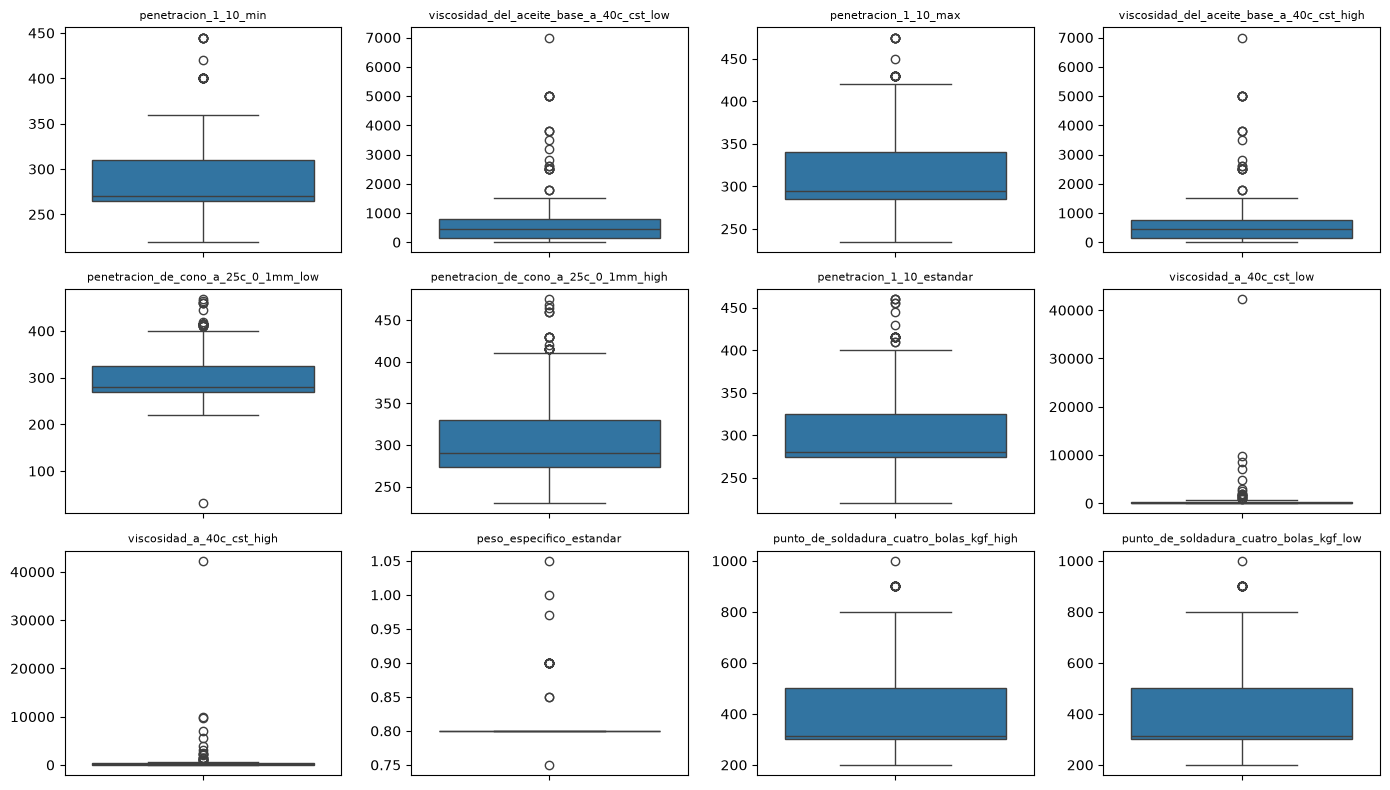

In [52]:
# 10b. Outliers (IQR rule): count per column and boxplots of the 12 most affected
num = df.select_dtypes("number")
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
n_out = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
print(n_out.head(12))

fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, c in zip(axes.ravel(), n_out.index[:12]):
    sns.boxplot(y=num[c], ax=ax)
    ax.set_title(c, fontsize=8)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [53]:
# 11. Export the cleaned data (processed/*.csv is git-ignored; encrypt and track with the DVC scripts to share it)
path = "../data/processed/DATOS_TEC_clean.csv"
df.to_csv(path, index=False)
print("saved:", df.shape, "| read back:", pd.read_csv(path).shape)

saved: (341, 84) | read back: (341, 84)
